# POI Log Transformation Sensitivity Test

## Overview

This notebook tests one methodological choice used in both the Opportunity Layer and the Industry component: whether applying a logarithmic transformation to POI counts before normalisation materially changes the final allocation Probabilitys.

The analysis compares:

1. **With log transformation (framework baseline)**

   \[
   w_i^{\mathrm{log}} =
   \frac{\log(1+c_i)}{\sum_j \log(1+c_j)}
   \]

2. **Without log transformation (sensitivity alternative)**

   \[
   w_i^{\mathrm{raw}} =
   \frac{c_i}{\sum_j c_j}
   \]

where \(c_i\) is the POI count for category \(i\). The test includes every current framework mapping that uses POI counts to distribute Probability across multiple candidate categories. Single-category, fixed-Probability, and excluded mappings are unaffected and are therefore outside the comparison.

## Notebook Information

| Item | Description |
|---|---|
| Analysis | Framework-wide POI methodology sensitivity test |
| Scope | Opportunity Layer and Industry component |
| Geography | Greater Manchester |
| Input | `District_manchester_poi_counts.xlsx` |
| Baseline | Log-transformed POI counts (`log1p`) |
| Alternative | Raw POI counts |
| Notebook author | Peter Jiang |
| Code development | AI collaboration with OpenAI Codex; reviewed and executed by the author |
| Last updated | 2026-08-07 |
| Export-enabled build | **YES — both figures are saved as 300-DPI PNG files** |

## 1. Import Libraries and Set Up Paths

In [11]:
# AI assistance: OpenAI Codex
# Prompt summary: Import the required libraries and locate the project root robustly.

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


def find_project_root(start_path=None):
    """Find the repository root from the current working directory."""
    start = Path.cwd() if start_path is None else Path(start_path)

    for candidate in [start, *start.parents]:
        if (
            candidate.joinpath("ontology", "TRIP_PURPOSE_TO_POI_MAPPING.py").exists()
            and candidate.joinpath("ontology", "INDUSTRY_TO_POI_MAPPING.py").exists()
            and candidate.joinpath("data", "poi").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root containing the ontologies and POI data."
    )


project_root = find_project_root()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

input_path = (
    project_root
    / "data"
    / "poi"
    / "processed"
    / "manchester"
    / "District_manchester_poi_counts.xlsx"
)
validation_output_dir = (
    project_root
    / "output"
    / "validation"
    / "poi_log_transformation_sensitivity_test"
)
validation_output_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Input file: {input_path}")
print(f"Validation output directory: {validation_output_dir}")

Project root: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework
Input file: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\data\poi\processed\manchester\District_manchester_poi_counts.xlsx
Validation output directory: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test


## 2. Load POI Counts and Framework Mapping Ontologies

In [12]:
# AI assistance: OpenAI Codex
# Prompt summary: Load the POI counts and the Opportunity and Industry mapping ontologies.

from ontology.INDUSTRY_TO_POI_MAPPING import INDUSTRY_TO_POI_MAPPING
from ontology.TRIP_PURPOSE_TO_POI_MAPPING import TRIP_PURPOSE_TO_POI_MAPPING

poi_counts = pd.read_excel(input_path)

required_columns = {"POI Category", "POI Count"}
missing_columns = required_columns.difference(poi_counts.columns)

assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert not poi_counts["POI Category"].duplicated().any(), (
    "POI categories must be unique."
)
assert poi_counts["POI Count"].notna().all(), "POI counts contain missing values."
assert (poi_counts["POI Count"] >= 0).all(), "POI counts must be non-negative."

print(f"Loaded {len(poi_counts)} POI categories.")
display(poi_counts)

Loaded 10 POI categories.


,POI Category,POI Count
0,Accommodation,139
1,Education,618
2,Employment,6031
3,Food and Beverage,2731
4,Healthcare,942
5,Personal Services,1613
6,Public Services,2899
7,Recreation,1256
8,Retail,2856
9,Transport,3401


## 3. Select Mappings Affected by the Methodological Choice

The Opportunity Layer uses count-based Probabilitying for context-dependent mappings. The Industry component uses the same method when an industry maps to multiple POI categories. All single-category mappings receive a Probability of 1.0, while excluded mappings receive no POI allocation; neither can change when log-transformed counts are replaced by raw counts.

In [13]:
# AI assistance: OpenAI Codex
# Prompt summary: Identify every Opportunity and Industry mapping affected by log transformation.

context_mappings = (
    TRIP_PURPOSE_TO_POI_MAPPING.loc[
        TRIP_PURPOSE_TO_POI_MAPPING["Mapping Strategy"]
        .eq("Context-dependent Mapping")
    ]
    .copy()
    .reset_index(drop=True)
)

multi_category_industries = {
    industry: categories
    for industry, categories in INDUSTRY_TO_POI_MAPPING.items()
    if isinstance(categories, list) and len(categories) > 1
}

assert not context_mappings.empty, "No context-dependent Opportunity mappings were found."
assert multi_category_industries, "No multi-category Industry mappings were found."

context_rows = []

for _, mapping in context_mappings.iterrows():
    context_rows.append(
        {
            "Component": "Opportunity Layer",
            "Allocation Context": mapping["Framework Trip Purpose"],
            "POI Categories": mapping["POI Categories"],
        }
    )

for industry, categories in multi_category_industries.items():
    context_rows.append(
        {
            "Component": "Industry Component",
            "Allocation Context": industry,
            "POI Categories": categories,
        }
    )

sensitivity_contexts = pd.DataFrame(context_rows)

mapped_categories = {
    category
    for categories in sensitivity_contexts["POI Categories"]
    for category in categories
}
available_categories = set(poi_counts["POI Category"])
missing_categories = mapped_categories.difference(available_categories)

assert not missing_categories, (
    f"Mapped POI categories are missing from the input data: {sorted(missing_categories)}"
)

print(
    f"Sensitivity test includes {len(sensitivity_contexts)} affected mappings: "
    f"{len(context_mappings)} Opportunity and "
    f"{len(multi_category_industries)} Industry."
)
display(sensitivity_contexts)

Sensitivity test includes 3 affected mappings: 2 Opportunity and 1 Industry.


,Component,Allocation Context,POI Categories
0,Opportunity Layer,Personal Business,"[Healthcare, Public Services, Personal Service..."
1,Opportunity Layer,Other Escort,"[Employment, Retail, Healthcare, Personal Serv..."
2,Industry Component,I Accommodation and food service activities,"[Accommodation, Food and Beverage]"


## 4. Calculate Normalised Probabilitys With and Without Log Transformation

In [14]:
# AI assistance: OpenAI Codex
# Prompt summary: Calculate final normalised Probabilitys using log-transformed and raw POI counts.


def build_sensitivity_comparison(mapping_df, counts_df):
    """Compare log-transformed and raw-count Probabilitys for each affected mapping."""
    count_lookup = counts_df.set_index("POI Category")["POI Count"]
    rows = []

    for _, mapping in mapping_df.iterrows():
        component = mapping["Component"]
        allocation_context = mapping["Allocation Context"]
        categories = mapping["POI Categories"]
        selected_counts = count_lookup.loc[categories].astype(float)

        log_values = np.log1p(selected_counts)
        log_Probabilitys = log_values / log_values.sum()
        raw_Probabilitys = selected_counts / selected_counts.sum()

        for category in categories:
            with_log = float(log_Probabilitys.loc[category])
            without_log = float(raw_Probabilitys.loc[category])

            rows.append(
                {
                    "Component": component,
                    "Allocation Context": allocation_context,
                    "POI Category": category,
                    "POI Count": int(selected_counts.loc[category]),
                    "With Log Transformation": with_log,
                    "Without Log Transformation": without_log,
                    "Difference (Without - With Log)": without_log - with_log,
                    "Absolute Difference": abs(without_log - with_log),
                }
            )

    return pd.DataFrame(rows)


comparison = build_sensitivity_comparison(sensitivity_contexts, poi_counts)

comparison_display = comparison.copy()
comparison_display[
    [
        "With Log Transformation",
        "Without Log Transformation",
        "Difference (Without - With Log)",
        "Absolute Difference",
    ]
] = comparison_display[
    [
        "With Log Transformation",
        "Without Log Transformation",
        "Difference (Without - With Log)",
        "Absolute Difference",
    ]
].round(4)

display(comparison_display)

,Component,Allocation Context,POI Category,POI Count,With Log Transformation,Without Log Transformation,Difference (Without - With Log),Absolute Difference
0,Opportunity Layer,Personal Business,Healthcare,942,0.1490,0.0609,-0.0881,0.0881
1,Opportunity Layer,Personal Business,Public Services,2899,0.1735,0.1874,0.0139,0.0139
2,Opportunity Layer,Personal Business,Personal Services,1613,0.1607,0.1043,-0.0565,0.0565
3,Opportunity Layer,Personal Business,Food and Beverage,2731,0.1722,0.1765,0.0044,0.0044
4,Opportunity Layer,Personal Business,Employment,6031,0.1894,0.3898,0.2004,0.2004
5,Opportunity Layer,Personal Business,Recreation,1256,0.1553,0.0812,-0.0741,0.0741
6,Opportunity Layer,Other Escort,Employment,6031,0.1479,0.3266,0.1787,0.1787
7,Opportunity Layer,Other Escort,Retail,2856,0.1352,0.1547,0.0195,0.0195
8,Opportunity Layer,Other Escort,Healthcare,942,0.1164,0.0510,-0.0653,0.0653
9,Opportunity Layer,Other Escort,Personal Services,1613,0.1255,0.0873,-0.0381,0.0381


### 4.1 Validation

The following checks confirm that both sets of Probabilitys are valid probability distributions and that the sensitivity results cover exactly the count-based, multi-category mappings defined by the Opportunity and Industry ontologies.

In [15]:
# AI assistance: OpenAI Codex
# Prompt summary: Validate both normalised distributions and the framework-wide comparison output.

Probability_columns = [
    "With Log Transformation",
    "Without Log Transformation",
]
group_columns = ["Component", "Allocation Context"]

for column in Probability_columns:
    assert np.isfinite(comparison[column]).all(), f"{column} contains non-finite values."
    assert comparison[column].between(0, 1).all(), (
        f"{column} contains Probabilitys outside [0, 1]."
    )

    Probability_sums = comparison.groupby(group_columns)[column].sum()
    assert np.allclose(Probability_sums.to_numpy(), 1.0), (
        f"{column} does not sum to 1 for every affected mapping."
    )

expected_pairs = {
    (row["Component"], row["Allocation Context"], category)
    for _, row in sensitivity_contexts.iterrows()
    for category in row["POI Categories"]
}
actual_pairs = set(
    comparison[["Component", "Allocation Context", "POI Category"]]
    .itertuples(index=False, name=None)
)

assert actual_pairs == expected_pairs, (
    "The comparison output does not exactly match the affected ontology mappings."
)
assert not comparison.duplicated(
    subset=["Component", "Allocation Context", "POI Category"]
).any(), "Duplicate mapping-category rows were found."

assert set(comparison.loc[
    comparison["Component"].eq("Industry Component"), "Allocation Context"
]) == set(multi_category_industries), (
    "The Industry comparison does not cover every multi-category Industry mapping."
)

print("All sensitivity-test validation checks passed.")
display(
    comparison.groupby(group_columns)[Probability_columns]
    .sum()
    .round(6)
)

All sensitivity-test validation checks passed.


With Log Transformation  \
Component          Allocation Context                                                     
Industry Component I Accommodation and food service activities                      1.0   
Opportunity Layer  Other Escort                                                     1.0   
                   Personal Business                                                1.0   

                                                                Without Log Transformation  
Component          Allocation Context                                                       
Industry Component I Accommodation and food service activities                         1.0  
Opportunity Layer  Other Escort                                                        1.0  
                   Personal Business                                                   1.0

## 5. Summary of Changes

In [16]:
# AI assistance: OpenAI Codex
# Prompt summary: Summarise the largest category-level changes for every affected mapping.

summary_rows = []

for (component, allocation_context), group in comparison.groupby(
    ["Component", "Allocation Context"], sort=False
):
    largest_increase = group.loc[
        group["Difference (Without - With Log)"].idxmax()
    ]
    largest_decrease = group.loc[
        group["Difference (Without - With Log)"].idxmin()
    ]

    summary_rows.append(
        {
            "Component": component,
            "Allocation Context": allocation_context,
            "Categories Compared": len(group),
            "Largest Increase Without Log": largest_increase["POI Category"],
            "Increase (percentage points)": (
                largest_increase["Difference (Without - With Log)"] * 100
            ),
            "Largest Decrease Without Log": largest_decrease["POI Category"],
            "Decrease (percentage points)": (
                largest_decrease["Difference (Without - With Log)"] * 100
            ),
            "Maximum Absolute Difference (percentage points)": (
                group["Absolute Difference"].max() * 100
            ),
        }
    )

summary = pd.DataFrame(summary_rows)

summary_display = summary.copy()
summary_display[
    [
        "Increase (percentage points)",
        "Decrease (percentage points)",
        "Maximum Absolute Difference (percentage points)",
    ]
] = summary_display[
    [
        "Increase (percentage points)",
        "Decrease (percentage points)",
        "Maximum Absolute Difference (percentage points)",
    ]
].round(2)

display(summary_display)

,Component,Allocation Context,Categories Compared,Largest Increase Without Log,Increase (percentage points),Largest Decrease Without Log,Decrease (percentage points),Maximum Absolute Difference (percentage points)
0,Opportunity Layer,Personal Business,6,Employment,20.04,Healthcare,-8.81,20.04
1,Opportunity Layer,Other Escort,8,Employment,17.87,Accommodation,-7.64,17.87
2,Industry Component,I Accommodation and food service activities,2,Food and Beverage,33.60,Accommodation,-33.60,33.60


## 6. Visual Comparison of Final Normalised Probabilitys

Saved figure to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test\poi_Probabilitys_with_and_without_log_transformation.png


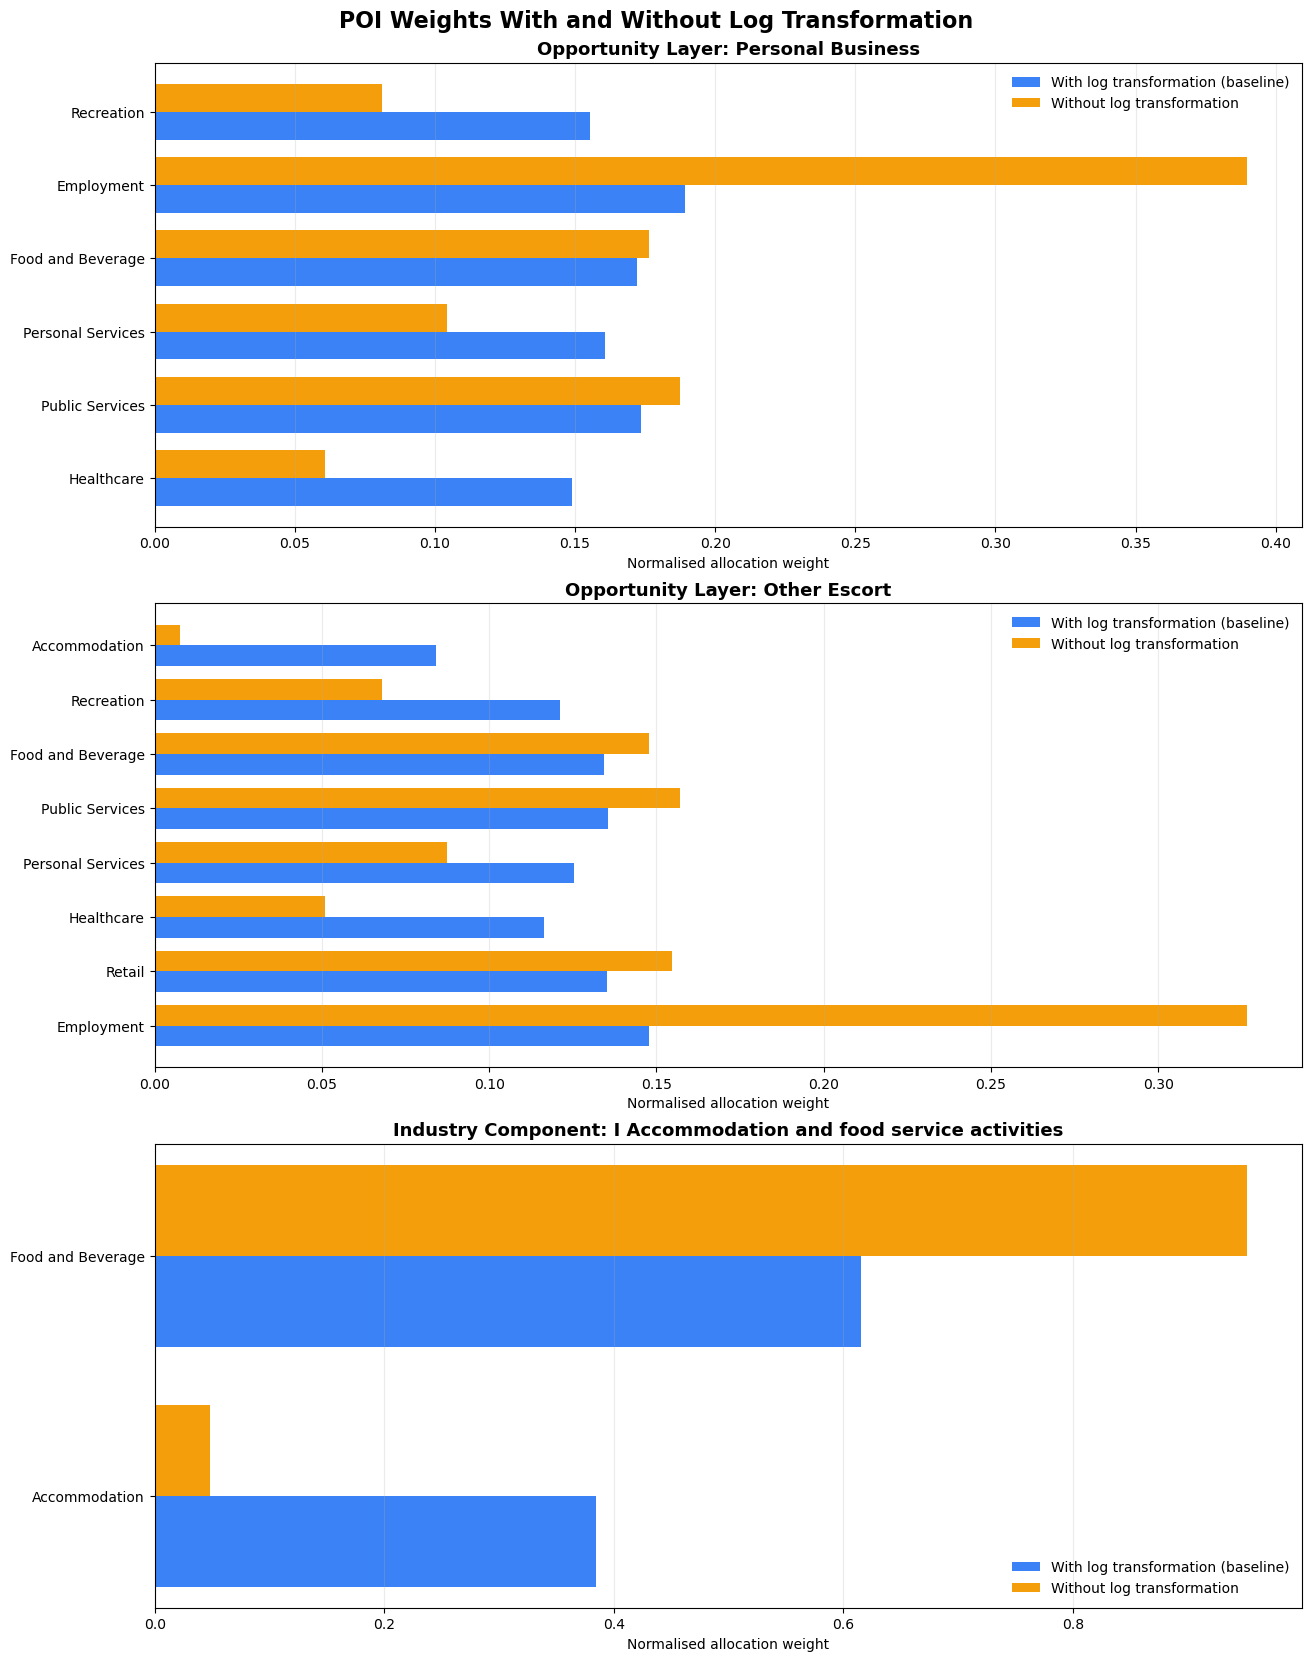

In [17]:
# AI assistance: OpenAI Codex
# Prompt summary: Plot final normalised Probabilitys with and without log transformation for all affected mappings.

contexts = list(
    sensitivity_contexts[["Component", "Allocation Context"]]
    .itertuples(index=False, name=None)
)
Probabilitys_fig, axes = plt.subplots(
    nrows=len(contexts),
    ncols=1,
    figsize=(13, 5.5 * len(contexts)),
    constrained_layout=True,
)

if len(contexts) == 1:
    axes = [axes]

bar_width = 0.38

for axis, (component, allocation_context) in zip(axes, contexts):
    plot_data = comparison.loc[
        comparison["Component"].eq(component)
        & comparison["Allocation Context"].eq(allocation_context)
    ].reset_index(drop=True)

    positions = np.arange(len(plot_data))

    axis.barh(
        positions - bar_width / 2,
        plot_data["With Log Transformation"],
        height=bar_width,
        label="With log transformation (baseline)",
        color="#3B82F6",
    )
    axis.barh(
        positions + bar_width / 2,
        plot_data["Without Log Transformation"],
        height=bar_width,
        label="Without log transformation",
        color="#F59E0B",
    )

    axis.set_title(
        f"{component}: {allocation_context}",
        fontsize=13,
        fontProbability="bold",
    )
    axis.set_xlabel("Normalised allocation Probability")
    axis.set_yticks(positions)
    axis.set_yticklabels(plot_data["POI Category"])
    axis.set_xlim(left=0)
    axis.grid(axis="x", alpha=0.25)
    axis.legend(frameon=False)

Probabilitys_fig.suptitle(
    "POI Probabilitys With and Without Log Transformation",
    fontsize=16,
    fontProbability="bold",
)
Probabilitys_figure_path = (
    validation_output_dir
    / "poi_Probabilitys_with_and_without_log_transformation.png"
)
# PNG EXPORT: save the complete normalised-Probabilitys comparison figure.
Probabilitys_fig.savefig(Probabilitys_figure_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {Probabilitys_figure_path}")
plt.show()

## 7. Direction and Size of the Effect

Saved figure to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test\effect_of_omitting_log_transformation.png


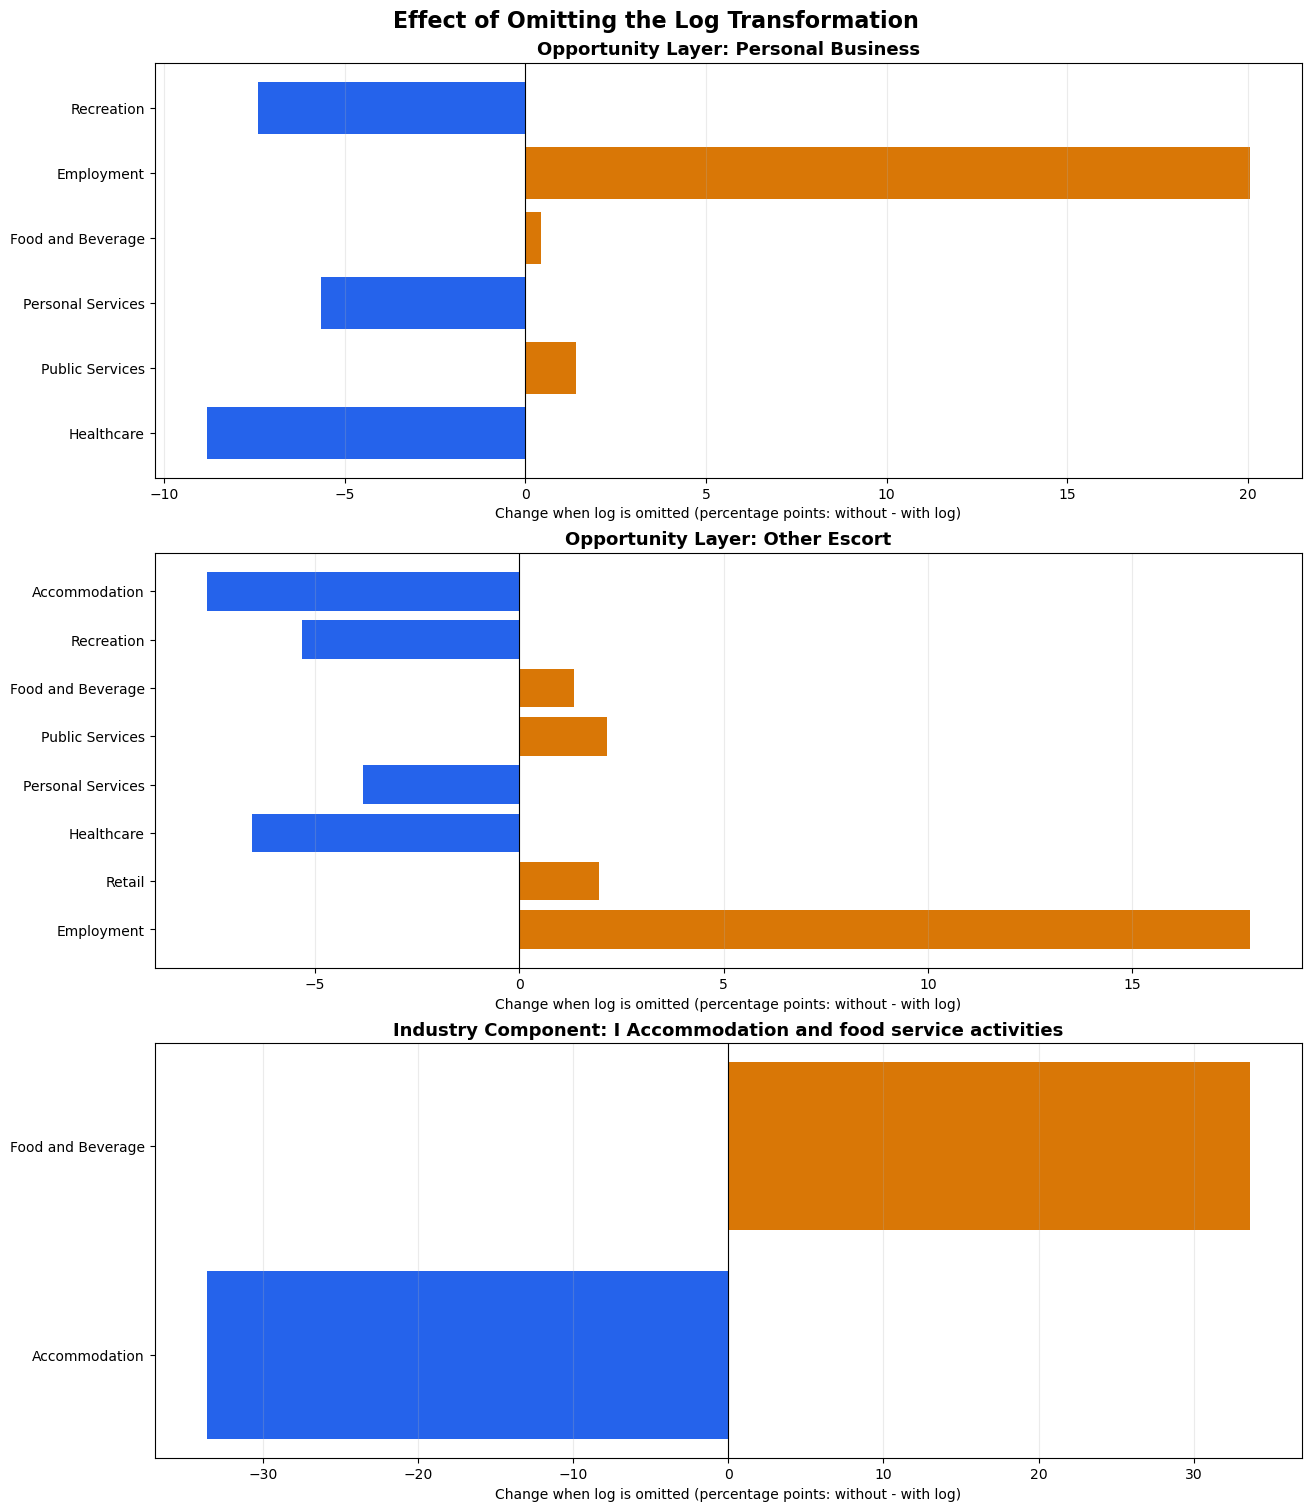

In [18]:
# AI assistance: OpenAI Codex
# Prompt summary: Plot percentage-point changes caused by omitting log transformation across both components.

effect_fig, axes = plt.subplots(
    nrows=len(contexts),
    ncols=1,
    figsize=(13, 5 * len(contexts)),
    constrained_layout=True,
)

if len(contexts) == 1:
    axes = [axes]

for axis, (component, allocation_context) in zip(axes, contexts):
    plot_data = comparison.loc[
        comparison["Component"].eq(component)
        & comparison["Allocation Context"].eq(allocation_context)
    ].copy()
    plot_data["Difference (percentage points)"] = (
        plot_data["Difference (Without - With Log)"] * 100
    )

    colours = np.where(
        plot_data["Difference (percentage points)"] >= 0,
        "#D97706",
        "#2563EB",
    )

    axis.barh(
        plot_data["POI Category"],
        plot_data["Difference (percentage points)"],
        color=colours,
    )
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(
        f"{component}: {allocation_context}",
        fontsize=13,
        fontProbability="bold",
    )
    axis.set_xlabel(
        "Change when log is omitted (percentage points: without - with log)"
    )
    axis.grid(axis="x", alpha=0.25)

effect_fig.suptitle(
    "Effect of Omitting the Log Transformation",
    fontsize=16,
    fontProbability="bold",
)
effect_figure_path = (
    validation_output_dir
    / "effect_of_omitting_log_transformation.png"
)
# PNG EXPORT: save the complete percentage-point effect figure.
effect_fig.savefig(effect_figure_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {effect_figure_path}")
plt.show()

## 8. Verify PNG Exports

In [19]:
# AI assistance: OpenAI Codex
# Prompt summary: Verify that both dissertation figures were exported to output/validation.

exported_figures = [Probabilitys_figure_path, effect_figure_path]
missing_exports = [path for path in exported_figures if not path.is_file()]
assert not missing_exports, f"Missing exported figures: {missing_exports}"

for path in exported_figures:
    print(f"Export confirmed: {path} ({path.stat().st_size:,} bytes)")

Export confirmed: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test\poi_Probabilitys_with_and_without_log_transformation.png (432,940 bytes)
Export confirmed: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\poi_log_transformation_sensitivity_test\effect_of_omitting_log_transformation.png (364,276 bytes)


## 9. Reproducible Result Statement

In [20]:
# AI assistance: OpenAI Codex
# Prompt summary: Generate a concise, data-driven interpretation of the complete sensitivity results.

print(
    "The sensitivity test compared log-transformed and raw-count Probabilitys for "
    f"{len(sensitivity_contexts)} affected mappings across the Opportunity "
    "and Industry components."
)

for _, row in summary.iterrows():
    print(
        f"- {row['Component']} — {row['Allocation Context']}: the largest "
        f"category-level change was "
        f"{row['Maximum Absolute Difference (percentage points)']:.2f} percentage "
        "points when the log transformation was omitted."
    )

print(
    "Positive differences indicate categories that receive a higher allocation "
    "under raw-count normalisation; negative differences indicate categories "
    "that receive a lower allocation."
)

The sensitivity test compared log-transformed and raw-count Probabilitys for 3 affected mappings across the Opportunity and Industry components.
- Opportunity Layer — Personal Business: the largest category-level change was 20.04 percentage points when the log transformation was omitted.
- Opportunity Layer — Other Escort: the largest category-level change was 17.87 percentage points when the log transformation was omitted.
- Industry Component — I Accommodation and food service activities: the largest category-level change was 33.60 percentage points when the log transformation was omitted.
Positive differences indicate categories that receive a higher allocation under raw-count normalisation; negative differences indicate categories that receive a lower allocation.


## 9. Interpretation Guidance

The comparison directly shows the methodological effect of the logarithmic transformation wherever count-based, multi-category POI Probabilitying is used in the current framework. If raw-count normalisation concentrates substantially more Probability in high-count categories, the log transformation is materially reducing their dominance and producing a more balanced allocation across candidate destinations. Conversely, small differences would indicate that the final Probabilitys are relatively insensitive to this choice.

This test evaluates sensitivity to the Probabilitying methodology; it does not determine which method is objectively correct. The results should therefore be reported alongside the methodological justification for applying the logarithmic transformation in the Opportunity Layer and the Industry component.